<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Wikipedia and Wikidata](https://github.com/Query-farm/vgi-wikipedia)

Connect Wikipedia articles with Wikidata statements and graph queries from SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-wikipedia/blob/main/notebooks/03_labels_are_not_item_keys.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-wikipedia/blob/main/notebooks/README.md)


## Labels are presentation; item IRIs are identity

**Can a lowercased name safely join two search results?** Search Wikidata for Mercury, select the planet and chemical element by their explicit item IDs, and inspect a bounded SPARQL response with English/French labels and an optional atomic number. The same-looking labels must not collapse two entities into one.

**Recorded public Wikidata data, CC0.** The candidate search and read-only SPARQL SELECT were independently captured from official public endpoints. A strict loopback server replays their original response bytes; the released worker parses dynamic RDF-term columns. No graph result or entity is invented. This is a two-item identity demonstration, not a general entity-resolution algorithm.

### Choose the display language

`LABEL_LANGUAGE` is **"en"** or **"fr"**; experiment from English to French. Both languages are already present in the fixed source response. This changes local display labels only; it does not translate text, query a different graph or change the item IDs. `DATA_MODE` is `recorded` by default, with an explicit public `live` mode and no fallback.

In [1]:
LABEL_LANGUAGE = "en"
DATA_MODE = "recorded"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.38":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.38"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402
from vgi_notebooks.bootstrap import prepare  # noqa: E402

check_runtime()
_companion_directory = prepare("wikipedia")

In [3]:
import json
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from notebook_support import configure, cleanup

state = configure("labels", LABEL_LANGUAGE, DATA_MODE)
replay = state["replay"]
theme()
session = connect(globals())
Path("artifacts").mkdir(exist_ok=True)
SOURCE = f"Wikidata CC0 · {DATA_MODE.title()} official Action API + SPARQL responses · explicit Q308 and Q925 slice"

### Use candidate descriptions before choosing IDs

The released worker runs in its own Python3.13 environment. Shared setup establishes UTC and a fresh empty temporary SQL-secret store with persistence disabled. These public reads need no API key.

A text search returns candidates, including a record label, automobile marque and other meanings. We explicitly select **Q308** (planet) and **Q925** (chemical element) for this comparison. Their returned descriptions help explain that choice; a shared label or search position does not establish identity. Materialize once before capture.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'wiki' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-wikipedia@v0.5.0 vgi-wikipedia-worker');
CREATE TABLE candidates AS SELECT * FROM wiki.wikidata.search('Mercury',count:=6,cache_seconds:=0);
CREATE TABLE chosen_items AS SELECT entity_id,label,description,url FROM candidates WHERE entity_id IN('Q308','Q925');
SELECT entity_id,label,description,match_text,entity_id IN(SELECT entity_id FROM chosen_items) AS chosen
FROM candidates ORDER BY entity_id;

,entity_id,label,description,match_text,chosen
0,Q1231263,Mercury,"commune in Savoie, France",Mercury,False
1,Q165745,Mercury Records,American record label,Mercury Records,False
2,Q308,Mercury,first planet from the Solar System and smalles...,Mercury,True
3,Q60009810,Mercury,male given name,Mercury,False
4,Q613883,Mercury,automobile marque of the Ford Motor Company,Mercury,False
5,Q925,mercury,chemical element with symbol Hg and atomic num...,mercury,True


### Read RDF terms without discarding their kinds

The complete SPARQL SELECT is visible inside the SQL call. Its two explicit IRIs bound the graph slice; two requested languages bound the labels. `OPTIONAL` keeps an item even when no atomic-number binding is returned. A missing binding becomes SQL NULL, while a bound numeric literal retains its lexical string and datatype.

The worker fetches SPARQL at bind time to discover dynamic columns. `CREATE TABLE` materializes that one result; subsequent displays read the local table. Avoid an extra DESCRIBE or EXPLAIN on the remote function, since that can make another source request. POST here carries a read-only SELECT, with no graph updates.

In [5]:
%%sql
CREATE TABLE terms AS SELECT * FROM wiki.wikidata.sparql('SELECT ?item ?label ?atomicNumber WHERE {
 VALUES ?item { <http://www.wikidata.org/entity/Q308> <http://www.wikidata.org/entity/Q925> }
 ?item <http://www.w3.org/2000/01/rdf-schema#label> ?label .
 FILTER(LANG(?label) IN ("en", "fr"))
 OPTIONAL { ?item <http://www.wikidata.org/prop/direct/P1086> ?atomicNumber }
} ORDER BY ?item LANG(?label)',cache_seconds:=0);

CREATE TABLE display_terms AS
SELECT regexp_extract(t.item.value,'(Q[0-9]+)$',1) AS entity_id,c.description,
 t.item.kind AS item_kind,t.item.value AS item_iri,
 t.label.value AS display_label,t.label.language AS label_language,t.label.datatype AS label_datatype,
 t.atomicNumber.kind AS number_kind,t.atomicNumber.value AS number_lexical,
 t.atomicNumber.datatype AS number_datatype,t.atomicNumber IS NULL AS number_unbound
FROM terms t JOIN chosen_items c ON t.item.value=c.url
WHERE t.label.language='{{LABEL_LANGUAGE}}';
SELECT * FROM display_terms ORDER BY entity_id;

,entity_id,description,item_kind,item_iri,display_label,label_language,label_datatype,number_kind,number_lexical,number_datatype,number_unbound
0,Q308,first planet from the Solar System and smalles...,iri,http://www.wikidata.org/entity/Q308,Mercury,en,http://www.w3.org/1999/02/22-rdf-syntax-ns#lan...,None,None,None,True
1,Q925,chemical element with symbol Hg and atomic num...,iri,http://www.wikidata.org/entity/Q925,mercury,en,http://www.w3.org/1999/02/22-rdf-syntax-ns#lan...,literal,80,http://www.w3.org/2001/XMLSchema#decimal,False


### Count identities before joining labels

Keep the full item IRI as the key. Lowercasing the two labels produces the same string in either selected language, so using that string as a key would merge the planet and element. The diagram below shows this actual many-to-one label mapping; it does not merge the underlying rows.

In [6]:
%%sql identity_frame <<
SELECT entity_id,item_iri,display_label,lower(display_label) AS folded_label,label_language,
       number_lexical,number_datatype,number_unbound FROM display_terms ORDER BY entity_id;

,entity_id,item_iri,display_label,folded_label,label_language,number_lexical,number_datatype,number_unbound
0,Q308,http://www.wikidata.org/entity/Q308,Mercury,mercury,en,None,None,True
1,Q925,http://www.wikidata.org/entity/Q925,mercury,mercury,en,80,http://www.w3.org/2001/XMLSchema#decimal,False


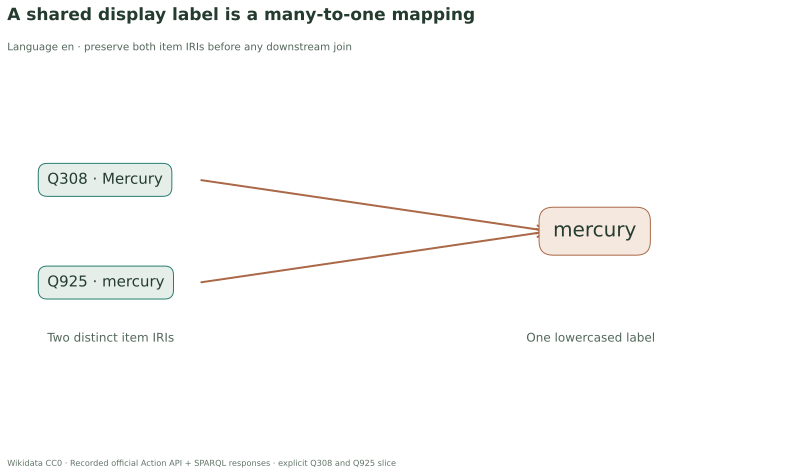

The selected **2 item IRIs map to 1 lowercased label** in en. Joining or deduplicating on `mercury` would lose the distinction between Q308 and Q925.

In [7]:
display(identity_frame)
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
rows = list(identity_frame.itertuples())
labels = sorted(identity_frame.folded_label.unique())
assert len(rows) == 2 and len(labels) == 1
for row, y in zip(rows, [0.70, 0.30], strict=True):
    ax.text(
        0.03,
        y,
        f"{row.entity_id} · {row.display_label}",
        ha="left",
        va="center",
        fontsize=15,
        bbox={"boxstyle": "round,pad=.6", "facecolor": "#e5eee9", "edgecolor": "#287D70"},
    )
    ax.add_patch(
        FancyArrowPatch(
            (0.23, y),
            (0.69, 0.50),
            arrowstyle="->",
            mutation_scale=20,
            color="#aa6846",
            linewidth=2,
        )
    )
ax.text(
    0.75,
    0.50,
    labels[0],
    ha="center",
    va="center",
    fontsize=20,
    bbox={"boxstyle": "round,pad=.7", "facecolor": "#f5e8df", "edgecolor": "#aa6846"},
)
ax.text(0.03, 0.07, "Two distinct item IRIs", fontsize=12, color="#52675a")
ax.text(0.66, 0.07, "One lowercased label", fontsize=12, color="#52675a")
finish(
    fig,
    "A shared display label is a many-to-one mapping",
    f"Language {LABEL_LANGUAGE} · preserve both item IRIs before any downstream join",
    name=f"identity-{LABEL_LANGUAGE}",
    source=SOURCE,
)
prose(
    f"The selected **{len(identity_frame)} item IRIs map to {len(labels)} lowercased label** in {LABEL_LANGUAGE}. Joining or deduplicating on `{labels[0]}` would lose the distinction between Q308 and Q925."
)

### Preserve typed values and unbound positions

The returned atomic-number literal for the element has lexical value `80` and datatype `xsd:decimal`; it is not an untyped string. The planet row has an unbound variable, represented by SQL NULL. That absence does not supply a numeric zero or prove a universal negative about every graph/property combination.

The matrix displays the returned term structure, not a numerical scale. Labels retain their language tag. Full datatype IRIs remain in the SQL table; shortened names below are display labels only.

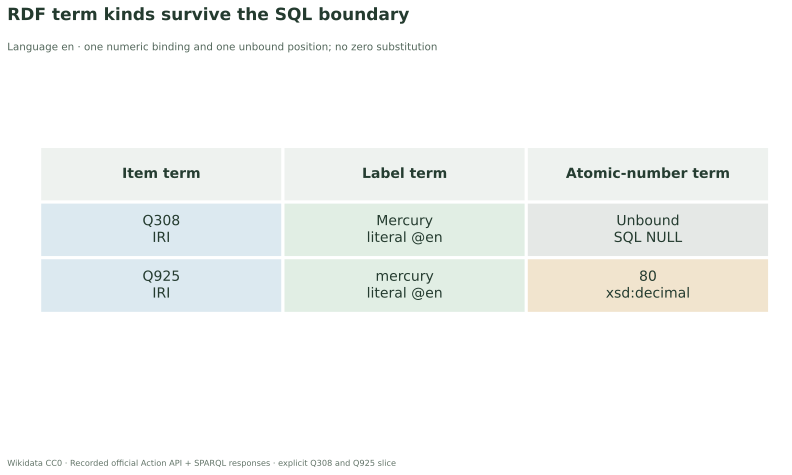

The lexical numeric value and its datatype remain paired. SQL NULL records an unbound variable; changing display language alters neither item identity nor the atomic-number binding.

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.axis("off")
cell_text = []
colors = []
for row in identity_frame.itertuples():
    number = "Unbound\nSQL NULL" if row.number_unbound else f"{row.number_lexical}\nxsd:decimal"
    cell_text.append(
        [f"{row.entity_id}\nIRI", f"{row.display_label}\nliteral @{row.label_language}", number]
    )
    colors.append(["#dce9f0", "#e1eee4", "#e5e8e6" if row.number_unbound else "#f1e4ce"])
table = ax.table(
    cellText=cell_text,
    cellColours=colors,
    colLabels=["Item term", "Label term", "Atomic-number term"],
    cellLoc="center",
    loc="center",
    bbox=[0.02, 0.18, 0.96, 0.65],
)
table.auto_set_font_size(False)
table.set_fontsize(14)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("white")
    cell.set_linewidth(3)
    if row == 0:
        cell.set_facecolor("#eef2ef")
        cell.set_text_props(weight="bold", color="#253d31")
finish(
    fig,
    "RDF term kinds survive the SQL boundary",
    f"Language {LABEL_LANGUAGE} · one numeric binding and one unbound position; no zero substitution",
    name=f"terms-{LABEL_LANGUAGE}",
    source=SOURCE,
)
prose(
    "The lexical numeric value and its datatype remain paired. SQL NULL records an unbound variable; changing display language alters neither item identity nor the atomic-number binding."
)

### Reconcile candidates, term structure and selected language

These checks validate this bounded observed slice. They do not guarantee that a future live search retains the same candidates or that labels are unique elsewhere. The exact recorded request audit expects one candidate search and one SPARQL POST; all displays use local materializations.

In [9]:
%%sql checks <<
SELECT 'Six distinct candidate IDs' AS check_name,count(*)=6 AND count(DISTINCT entity_id)=6 AS passed FROM candidates
UNION ALL SELECT 'Both explicit IDs were discovered',count(*)=2 AND count(DISTINCT entity_id)=2 FROM chosen_items
UNION ALL SELECT 'Four item-language source rows',count(*)=4 AND count(DISTINCT(item.value,label.language))=4 FROM terms
UNION ALL SELECT 'Item terms retain IRI kind',bool_and(item.kind='iri' AND item.datatype IS NULL AND item.language IS NULL) FROM terms
UNION ALL SELECT 'Two selected-language rows',count(*)=2 AND bool_and(label_language='{{LABEL_LANGUAGE}}') FROM display_terms
UNION ALL SELECT 'Language literals retain datatype',bool_and(label_datatype='http://www.w3.org/1999/02/22-rdf-syntax-ns#langString') FROM display_terms
UNION ALL SELECT 'Numeric binding retains lexical value and decimal datatype',count(*) FILTER(WHERE number_kind='literal' AND number_lexical='80' AND number_datatype='http://www.w3.org/2001/XMLSchema#decimal')=1 FROM display_terms
UNION ALL SELECT 'Unbound is retained as SQL NULL',count(*) FILTER(WHERE number_unbound AND number_lexical IS NULL AND number_datatype IS NULL)=1 FROM display_terms
UNION ALL SELECT 'Lowercasing would collapse the two identities',count(DISTINCT item_iri)=2 AND count(DISTINCT lower(display_label))=1 FROM display_terms;

In [10]:
%%sql raw_terms <<
SELECT * FROM terms ORDER BY item.value,label.language;

In [11]:
display(checks)
assert checks.passed.fillna(False).all()
if replay:
    assert (
        Counter(replay.requests) == Counter({"entity-search": 1, "typed-labels": 1})
        and not replay.rejected
    )
prose(
    "All nine SQL checks passed. The recorded request audit contains one candidate read and one read-only SPARQL POST."
    if replay
    else "All nine SQL checks passed on the explicit live public slice."
)
Path("artifacts/analysis-03.json").write_text(
    json.dumps(
        {
            "language": LABEL_LANGUAGE,
            "mode": DATA_MODE,
            "display": identity_frame.to_dict("records"),
            "raw_terms": raw_terms.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": replay.requests if replay else None,
        },
        indent=2,
        default=str,
    )
);

,check_name,passed
0,Six distinct candidate IDs,True
1,Both explicit IDs were discovered,True
2,Four item-language source rows,True
3,Item terms retain IRI kind,True
4,Two selected-language rows,True
5,Language literals retain datatype,True
6,Numeric binding retains lexical value and deci...,True
7,Unbound is retained as SQL NULL,True
8,Lowercasing would collapse the two identities,True


All nine SQL checks passed. The recorded request audit contains one candidate read and one read-only SPARQL POST.

### Experiment: display the already-fetched French labels

Change **LABEL_LANGUAGE from "en" to "fr"** in a separate recorded-mode run. Both figures and selected label strings change, but the two item IRIs, the four raw item-language rows, the lexical numeric value `80`, its decimal datatype and the unbound planet position stay fixed. The lowercased label still has two distinct source identities. Reset to English afterward.

This is a local display experiment. `DATA_MODE="live"` is a separate new retrieval, with explicit failures and no recorded fallback.

In [12]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
cleanup(state)

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-wikipedia](https://github.com/Query-farm/vgi-wikipedia)